<a href="https://colab.research.google.com/github/Samarbal/Deep-Learning-/blob/main/Advanced_RNNs_(LSTM_%26_Vanishing_Gradients).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Advanced RNNs (LSTM & Vanishing Gradients)

Samar Mohammed Balousha

2320222601

### Task 1: Vanishing Gradient Simulation

In [10]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
steps = 40

# Experiment A: Vanishing Gradient
gradient_a = 0.8
history_a = []
current_grad = 1.0

for i in range(steps):
    current_grad *= gradient_a
    history_a.append(current_grad)



# Experiment B: Exploding Gradient
gradient_b = 1.05
history_b = []
current_grad = 1.0

for i in range(steps):
    current_grad *= gradient_b
    history_b.append(current_grad)

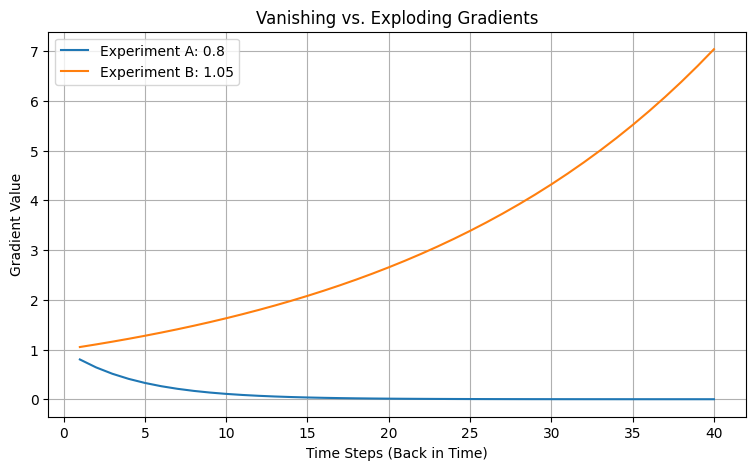

Experiment A Final Gradient: 0.00013292279957849188
Experiment B Final Gradient: 7.03998871212466


In [12]:



# Plot both experiments
plt.figure(figsize=(9, 5))

plt.plot(range(1, steps + 1), history_a,
         label="Experiment A: 0.8")
plt.plot(range(1, steps + 1), history_b,
         label="Experiment B: 1.05")

plt.title("Vanishing vs. Exploding Gradients")
plt.xlabel("Time Steps (Back in Time)")
plt.ylabel("Gradient Value")
plt.legend()
plt.grid(True)
plt.show()

print("Experiment A Final Gradient:", history_a[-1])
print("Experiment B Final Gradient:", history_b[-1])




**Question 1: What happens to the gradient in Experiment A (0.8)?**

In Experiment A, the gradient decreases exponentially as it propagates backward through 40 time steps, approaching zero. This illustrates the vanishing gradient problem, which makes learning long-term dependencies difficult.

**Question 2: What happens in Experiment B (1.05)?**

In Experiment B, the gradient increases exponentially because it is repeatedly multiplied by a value greater than 1. This illustrates the exploding gradient problem, where gradients can become excessively large and cause unstable training.

### Task 2: Building an LSTM Model

In [13]:

from tensorflow.keras import layers, models

# Build the LSTM model
model_lstm = models.Sequential([
    layers.Input(shape=(20, 1)),  # 20 time steps
    layers.LSTM(units=64), # 64 lstm unit
    layers.Dense(1)
])

# Display the model architecture
model_lstm.summary()



Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_5 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

* prameters for RNN = unit * (unit + input_dim + 1)

* parameters for LSTM = 4 * (unit * (unit + input_dim + 1))

* dense(1) = 64*1+1=65

* Parameters for LSTM = 4 *(64( 64 +1+1 ))= 16961

* The LSTM layer produces an output shape of (None, 64)

### Task 3 — Parameter Complexity Comparison

In [14]:

import tensorflow as tf
from tensorflow.keras import layers

# Create the recurrent layers
rnn_layer = layers.SimpleRNN(units=64)
lstm_layer = layers.LSTM(units=64)

# Build both layers using the same input shape
rnn_layer.build((None, 15, 1))
lstm_layer.build((None, 15, 1))

# Compare trainable parameters
print("SimpleRNN Parameters:", rnn_layer.count_params())
print("LSTM Parameters:", lstm_layer.count_params())


SimpleRNN Parameters: 4224
LSTM Parameters: 16896


**Question: Why does an LSTM layer have significantly more parameters than a SimpleRNN layer for the same number of units?**

**Answer**:

An LSTM layer has more parameters because it uses four sets of computations: the input gate, forget gate, output gate, and candidate cell state.

 parameters for LSTM = 4 * (unit * (unit + input_dim + bias ))

Each requires its own weights and biases, making the LSTM parameter count four times that of a SimpleRNN with the same input size and number of units.

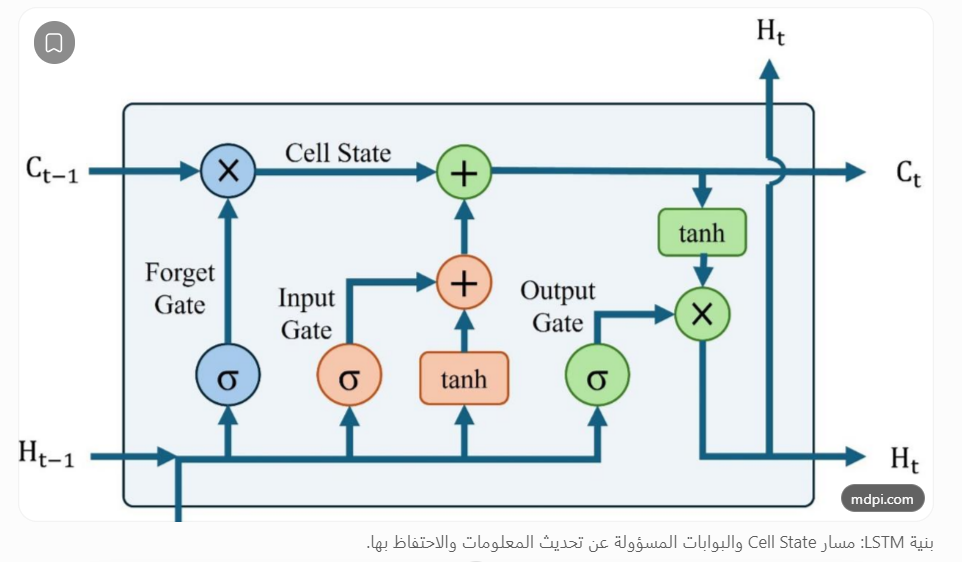

**Understanding LSTM Gates**


LSTM uses a cell state to store information over time. It controls this information using three gates and a candidate cell state:

- **Forget Gate:** Decides what old information to forget or keep.
- **Input Gate:** Controls how much new information is added to memory.
- **Candidate Cell State:** Creates new candidate information to update the memory.
- **Output Gate:** Controls what information is used to produce the hidden state.

These components help LSTM learn long-term dependencies and reduce the vanishing gradient problem compared to a SimpleRNN.